11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
        CNN - MNIST IMAGE CLASSIFICATION
Original training data: (60000, 28, 28)
Original testing data : (10000, 28, 28)

Training data: (10000, 28, 28, 1)
Testing data : (2000, 28, 28, 1)

MODEL SUMMARY


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)


TRAINING CNN
Epoch 1/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - accuracy: 0.7750 - loss: 0.8147 - val_accuracy: 0.9190 - val_loss: 0.2755
Epoch 2/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9436 - loss: 0.2075 - val_accuracy: 0.9500 - val_loss: 0.1836
Epoch 3/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9623 - loss: 0.1351 - val_accuracy: 0.9590 - val_loss: 0.1382

MODEL EVALUATION
Test Loss     : 0.1479
Test Accuracy : 95.20%

IMAGE CLASSIFICATION RESULTS
Image 1: Actual = 7 | Predicted = 7 | Confidence = 99.96%
Image 2: Actual = 2 | Predicted = 2 | Confidence = 99.87%
Image 3: Actual = 1 | Predicted = 1 | Confidence = 99.86%
Image 4: Actual = 0 | Predicted = 0 | Confidence = 99.98%
Image 5: Actual = 4 | Predicted = 4 | Confidence = 99.79%
Image 6: Actual = 1 | Predicted = 1 | Confidence = 99.90%
Image 7: Actual = 4 | Predicted = 4 | Confidence = 99.79%
Image 8: Actual = 9 | Predicted = 9 | Confidence = 68.72%
Image 9: Actual = 5 | Predicted = 6 | Confidence = 5

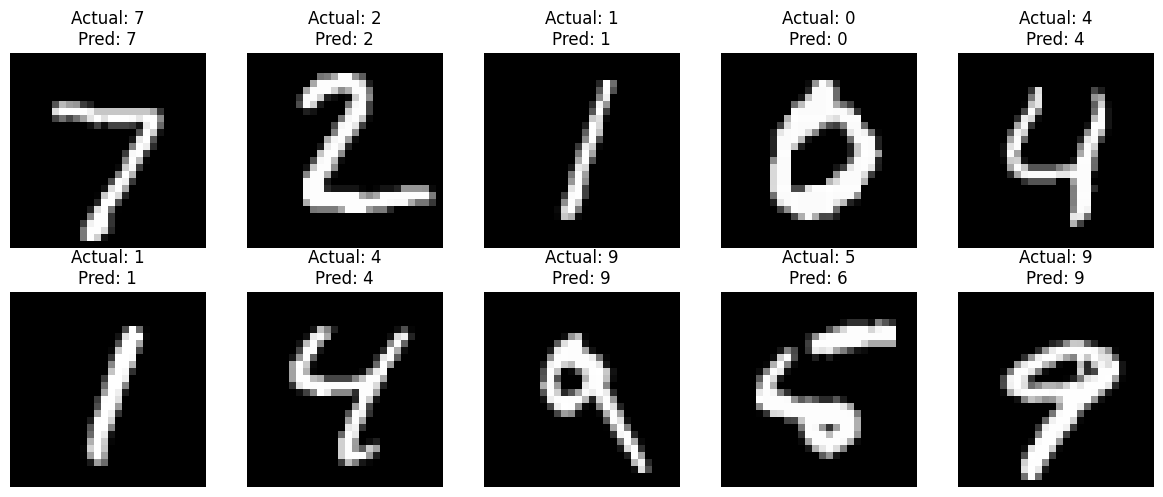

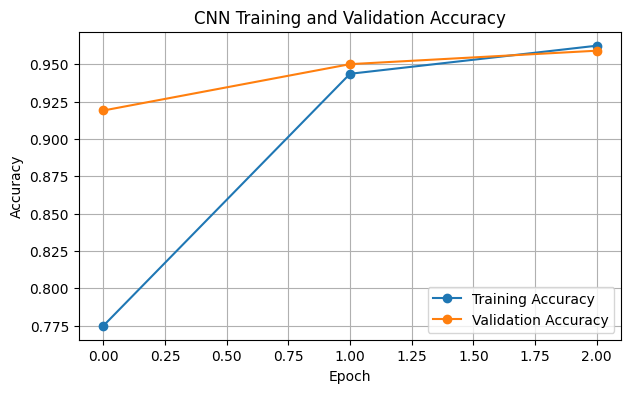

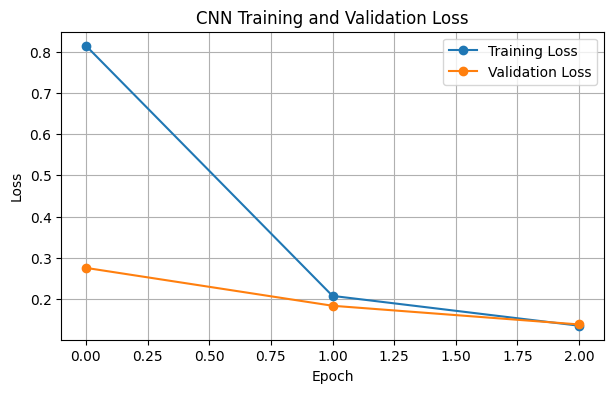



       CNN EXPERIMENT COMPLETED
Training Images : 10000
Testing Images  : 2000
Test Accuracy   : 95.20%


In [ ]:
# ============================================================
# SIMPLE CNN FOR IMAGE CLASSIFICATION
# Dataset: MNIST
# Google Colab - FAST VERSION
# ============================================================

import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense
)

# ============================================================
# 1. LOAD MNIST DATASET
# ============================================================

(X_train, y_train), (X_test, y_test) = \
    tf.keras.datasets.mnist.load_data()

print("=" * 55)
print("        CNN - MNIST IMAGE CLASSIFICATION")
print("=" * 55)

print("Original training data:", X_train.shape)
print("Original testing data :", X_test.shape)


# ============================================================
# 2. USE SMALL SUBSET FOR FAST TRAINING
# ============================================================

X_train = X_train[:10000]
y_train = y_train[:10000]

X_test = X_test[:2000]
y_test = y_test[:2000]


# ============================================================
# 3. PREPROCESSING
# ============================================================

# Normalize pixels from 0-255 to 0-1

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0


# CNN expects:
# (images, height, width, channels)

X_train = X_train.reshape(
    -1, 28, 28, 1
)

X_test = X_test.reshape(
    -1, 28, 28, 1
)


print("\nTraining data:", X_train.shape)
print("Testing data :", X_test.shape)


# ============================================================
# 4. CLASS NAMES
# ============================================================

class_names = [
    "0", "1", "2", "3", "4",
    "5", "6", "7", "8", "9"
]


# ============================================================
# 5. BUILD SIMPLE CNN
# ============================================================

model = Sequential([

    # Input
    Input(shape=(28, 28, 1)),

    # Convolution Layer 1
    Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    # Pooling
    MaxPooling2D(
        (2, 2)
    ),

    # Convolution Layer 2
    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    # Pooling
    MaxPooling2D(
        (2, 2)
    ),

    # Flatten
    Flatten(),

    # Fully Connected Layer
    Dense(
        64,
        activation="relu"
    ),

    # Output Layer
    Dense(
        10,
        activation="softmax"
    )
])


# ============================================================
# 6. MODEL SUMMARY
# ============================================================

print("\nMODEL SUMMARY")
print("=" * 55)

model.summary()


# ============================================================
# 7. COMPILE
# ============================================================

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================================
# 8. TRAIN
# ============================================================

print("\nTRAINING CNN")
print("=" * 55)

history = model.fit(

    X_train,
    y_train,

    epochs=3,

    batch_size=128,

    validation_split=0.1,

    verbose=1
)


# ============================================================
# 9. EVALUATE
# ============================================================

print("\nMODEL EVALUATION")
print("=" * 55)

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : {test_accuracy * 100:.2f}%"
)


# ============================================================
# 10. PREDICT TEST IMAGES
# ============================================================

predictions = model.predict(
    X_test[:10],
    verbose=0
)

predicted_classes = predictions.argmax(
    axis=1
)


# ============================================================
# 11. DISPLAY PREDICTIONS
# ============================================================

print("\nIMAGE CLASSIFICATION RESULTS")
print("=" * 55)

for i in range(10):

    actual = class_names[
        y_test[i]
    ]

    predicted = class_names[
        predicted_classes[i]
    ]

    confidence = (
        predictions[i][predicted_classes[i]]
        * 100
    )

    print(
        f"Image {i+1}: "
        f"Actual = {actual} | "
        f"Predicted = {predicted} | "
        f"Confidence = {confidence:.2f}%"
    )


# ============================================================
# 12. DISPLAY SAMPLE IMAGES
# ============================================================

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[i].squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[i]}\n"
        f"Pred: {predicted_classes[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 13. PLOT ACCURACY
# ============================================================

plt.figure(figsize=(7, 4))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "CNN Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 14. PLOT LOSS
# ============================================================

plt.figure(figsize=(7, 4))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "CNN Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 15. FINAL RESULT
# ============================================================

print("\n")
print("=" * 55)
print("       CNN EXPERIMENT COMPLETED")
print("=" * 55)

print(
    f"Training Images : {len(X_train)}"
)

print(
    f"Testing Images  : {len(X_test)}"
)

print(
    f"Test Accuracy   : "
    f"{test_accuracy * 100:.2f}%"
)

print("=" * 55)